# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko,
                                                   add_model_name_to_df)

from halcyon.results.plot_from_df import plot_model_plots, plot_per_gene_mse_heatmap, rotate_x_tick_labels, wrap_titles

from halcyon.results.DfColumnNames import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

In [2]:
print(mlflow.get_tracking_uri())
[f"{experiment.name=}" for experiment in mlflow.search_experiments()]
mlflow.set_experiment("Halcyon sandbox experiment")
mlflow.set_experiment_tag("Tool name", "HALCYON") 

https://mlflow.cropresilience.org


In [3]:
simulation_run_id_to_use = "20ac828ac40844cdb32526682c0d21c5"

run = mlflow.get_run(simulation_run_id_to_use)

params = run.data.params
print(params)
print(run.data.tags.get('mlflow.source.git.commit'))

{'nr_genes': '50', 'sparsity': '0.1', 'num_modules': '5', 'noise_level': 'ALLNOISE', 'seed': '174'}
None


In [4]:
parent_run_id_search_string = f"tags.mlflow.parentRunId= '{simulation_run_id_to_use}'" 
runs_to_download = mlflow.search_runs(filter_string=parent_run_id_search_string, output_format="list")

In [ ]:
len(runs_to_download)

In [ ]:
runs_to_download[0].data.params

In [5]:
raw_df_download = create_tidy_df_from_mlflow_runs(runs_to_download)
with_model_name = add_model_name_to_df(raw_df_download)

2026-02-19 11:24:46,327 - INFO - Downloading artifacts for run f66dd48ba08944e8a9710e7bd8d678ed


2026-02-19 11:24:47,383 - INFO - Downloading artifacts for run 2dac2b6086654c39bee8e774a24fbd80


2026-02-19 11:24:48,311 - INFO - Downloading artifacts for run 2a4fa94bc40d4160a45c99706804404d


2026-02-19 11:24:49,284 - INFO - Downloading artifacts for run a9f60f4e0ed84a4c8e06d5be67f3c510


2026-02-19 11:24:50,220 - INFO - Downloading artifacts for run a5f36545f65f449dbaad42564ea22082


2026-02-19 11:24:51,171 - INFO - Downloading artifacts for run d9bec2dd1a9e45a9a55b358573a60b14


2026-02-19 11:24:52,157 - INFO - Downloading artifacts for run 1d5faec1a69b4f9d84facfe8bfd71d03


2026-02-19 11:24:53,036 - INFO - Downloading artifacts for run d027a18451be4ca48d6e1e35cdcb8f77


2026-02-19 11:24:54,664 - INFO - Getting model name for run_id f66dd48ba08944e8a9710e7bd8d678ed
2026-02-19 11:24:54,807 - INFO - Getting model name for run_id 2dac2b6086654c39bee8e774a24fbd80
2026-02-19 11:24:54,952 - INFO - Getting model name for run_id 2a4fa94bc40d4160a45c99706804404d
2026-02-19 11:24:55,100 - INFO - Getting model name for run_id a9f60f4e0ed84a4c8e06d5be67f3c510
2026-02-19 11:24:55,251 - INFO - Getting model name for run_id a5f36545f65f449dbaad42564ea22082
2026-02-19 11:24:55,398 - INFO - Getting model name for run_id d9bec2dd1a9e45a9a55b358573a60b14
2026-02-19 11:24:55,545 - INFO - Getting model name for run_id 1d5faec1a69b4f9d84facfe8bfd71d03
2026-02-19 11:24:55,690 - INFO - Getting model name for run_id d027a18451be4ca48d6e1e35cdcb8f77


## Make subsets of data for plotting

In [6]:
# Split into Single and Double knockout
tidy_df_single_ko, tidy_df_double_ko = split_df_into_single_and_double_ko(with_model_name)

In [ ]:
tidy_df_single_ko[DfColumnNames.MODEL_COL].value_counts()

In [ ]:
def df_selection_function(df):
    node_index_regex = '|'.join([f'{i}' for i in range(4)])
    genes_to_show_regex = rf"Node_(?:{node_index_regex})(?:[.,]|$)"

    models_to_show = ["PhoenixAddAndProdLayers", "PyTorchODE", DfColumnNames.GROUND_TRUTH_COL, "HybridModel"]
    models_to_show_regex = "|".join(models_to_show)

    index_to_select = ((df[DfColumnNames.GENE_COL].str.contains(genes_to_show_regex))
            & (df[DfColumnNames.CONDITION_COL].str.contains(genes_to_show_regex))
            & (df[DfColumnNames.MODEL_COL].str.contains(models_to_show_regex)))
    filtered_df =  df[index_to_select]
    assert len(filtered_df), 'Filtered dataframe is empty'
    return filtered_df

In [ ]:
df_selection_function(tidy_df_single_ko).sum()

In [ ]:
filtered_df_single_ko = df_selection_function(tidy_df_single_ko)
filtered_df_double_ko = df_selection_function(tidy_df_double_ko)

# Plotting

## Lineplots

### Single KO

In [ ]:
# FOr each of this knockout, plot predicted vs real for all model (for subset of genes)

# Plot for single KO
g = plot_model_plots(filtered_df_single_ko)
wrap_titles(g)

### Double KO

In [ ]:
g = plot_model_plots(filtered_df_double_ko)
wrap_titles(g)

## Now the heatmaps

### Single KO

In [ ]:
from matplotlib.colors import Normalize

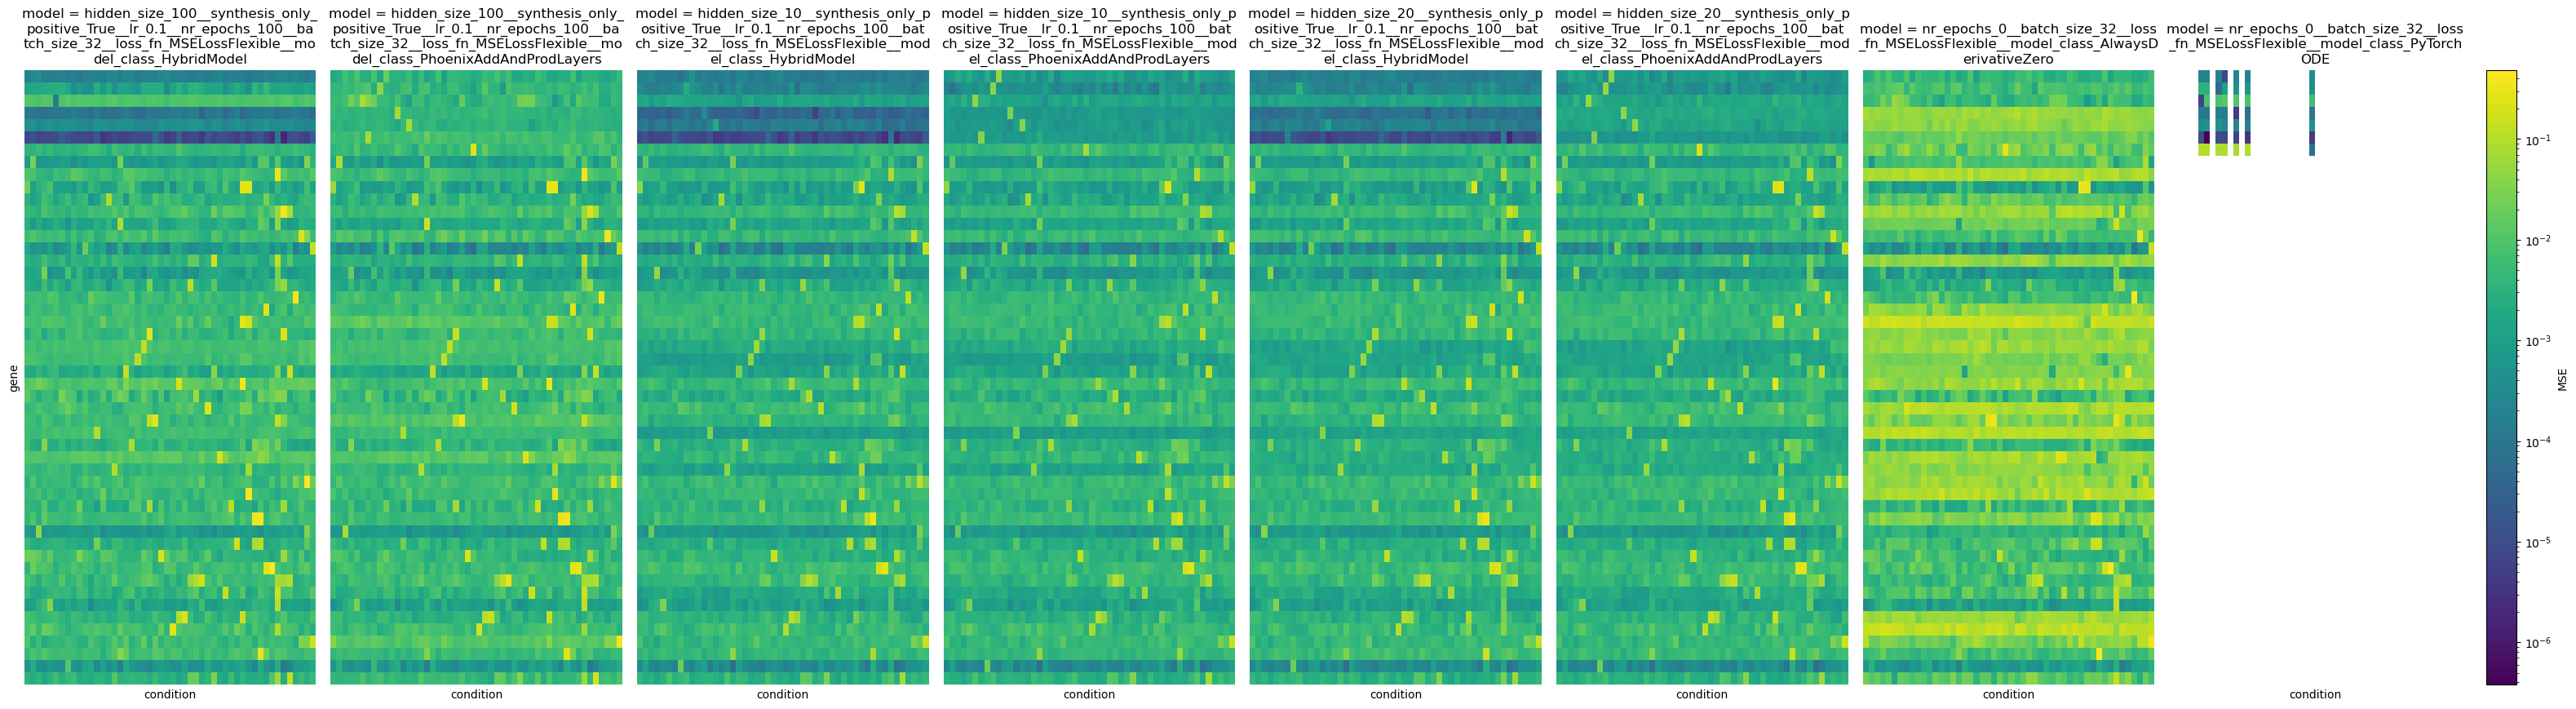

In [7]:
# Calculate the MSE heatmap that we've shown before
g = plot_per_gene_mse_heatmap(tidy_df_single_ko, robust_cmap=False)
wrap_titles(g)

### Double KO

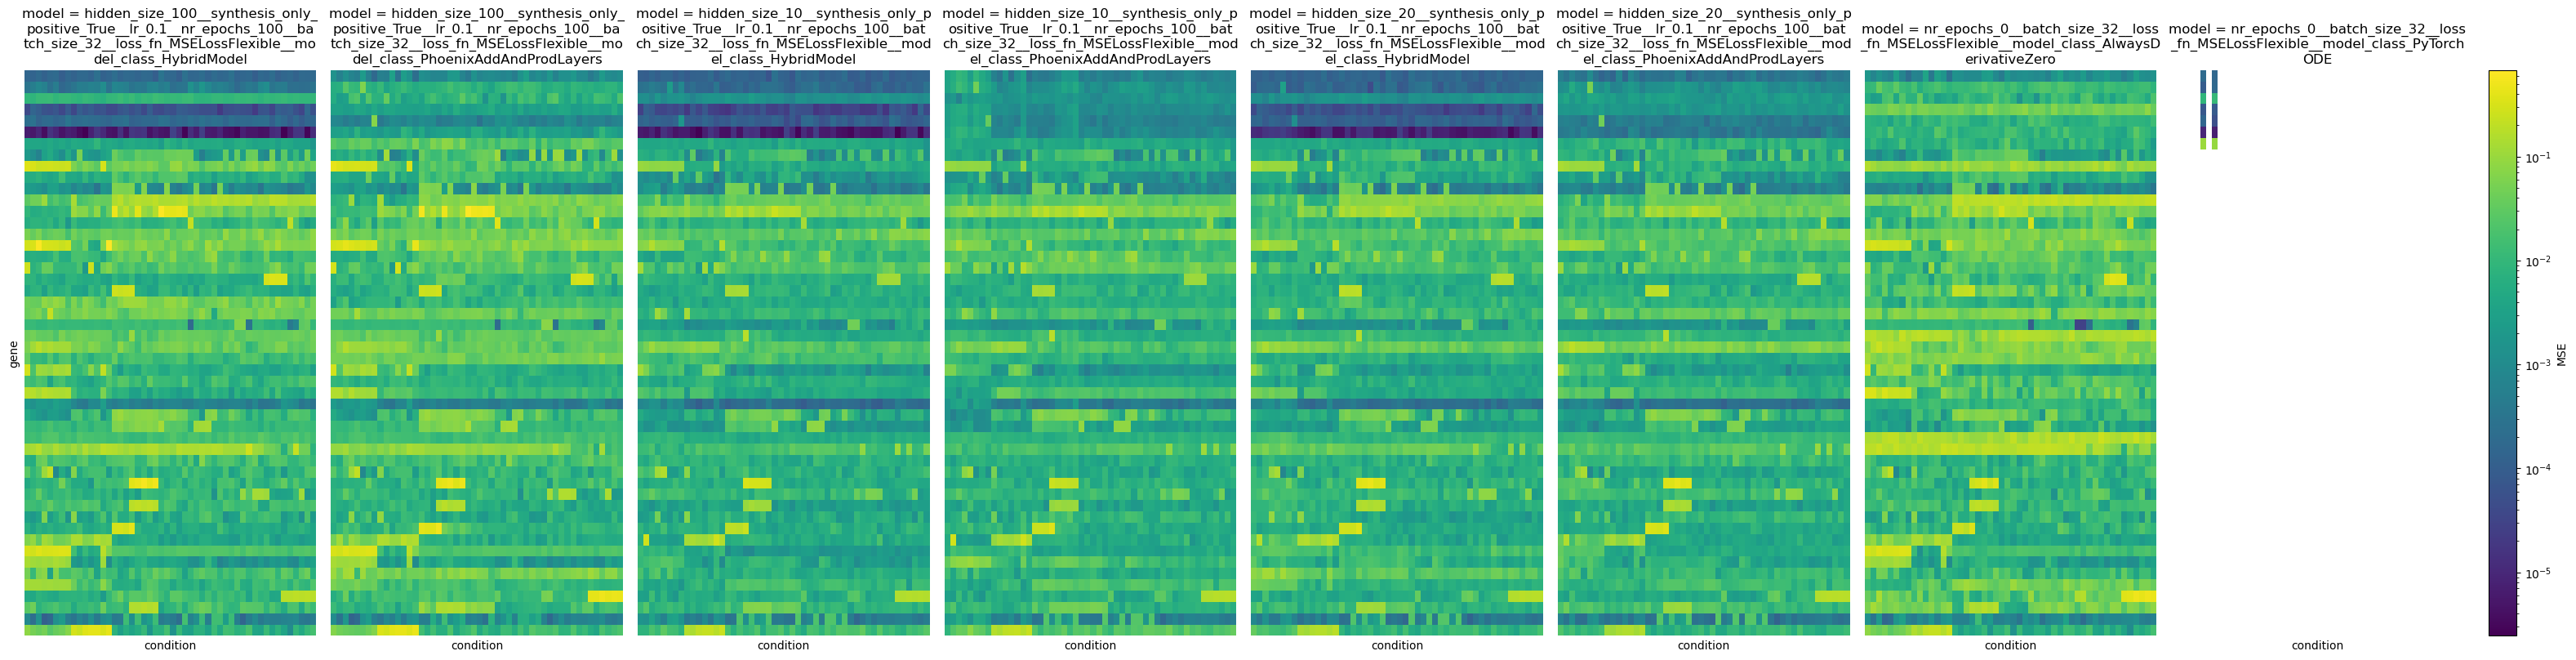

In [8]:
# Calculate the MSE heatmap that we've shown before
g = plot_per_gene_mse_heatmap(tidy_df_double_ko, robust_cmap=False)
wrap_titles(g)